Predict future averge price of Miscellaneous Food monthly by using SARIMAX model and Linear Regression Model.

### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# LinearRegression
from sklearn.linear_model import LinearRegression

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2009-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DMFM = data.copy()
DMFM = DMFM[DMFM['category']=='miscellaneous food']
DMFM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
80,1/15/2008,Shan (South),Taunggyi,Taunggyi,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,121.21,0.0681
85,2/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
160,2/15/2008,Shan (South),Taunggyi,Taunggyi,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,121.21,0.0681
239,3/15/2008,Shan (South),Taunggyi,Taunggyi,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,121.21,0.0681


In [13]:
DMFM = DMFM[['date', 'price']]
DMFM['date'] = pd.to_datetime(DMFM['date'])
mask = (DMFM['date']>=obv_st_date) & (DMFM['date']<=obv_end_date)
DMFM = DMFM.loc[mask]
DMFM = DMFM.set_index('date')
DMFM.head()

,price
date,
2008-01-15,242.42
2008-01-15,121.21
2008-02-15,242.42
2008-02-15,121.21
2008-03-15,121.21


In [14]:
DMFM = DMFM.resample('MS').mean()
DMFM.head()

,price
date,
2008-01-01,181.815
2008-02-01,181.815
2008-03-01,121.210
2008-04-01,439.395
2008-05-01,484.850


In [15]:
DMFM.shape

(169, 1)

In [16]:
price = DMFM['price']
date = DMFM.index

##### Normalization data

In [17]:
scaler = MinMaxScaler()

In [18]:
DMFM_nor = scaler.fit_transform(DMFM)
DMFM_nor = pd.DataFrame(DMFM_nor)
DMFM_nor.head()

,0
0,0.097945
1,0.097945
2,0.000000
3,0.514227
4,0.587688


In [19]:
DMFM_nor['date']=date
DMFM_nor = DMFM_nor.set_index('date')
DMFM_nor.columns=['price']
DMFM_nor.head()

,price
date,
2008-01-01,0.097945
2008-02-01,0.097945
2008-03-01,0.000000
2008-04-01,0.514227
2008-05-01,0.587688


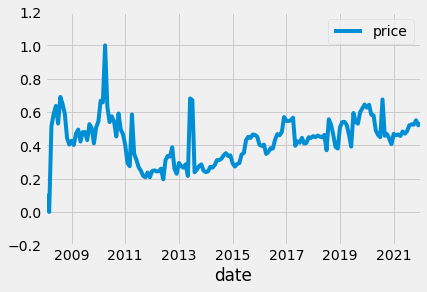

In [20]:
DMFM_nor.plot(grid=True)
plt.show()

It has no trend

##### Checking Random Walk

In [21]:
RW_DMFM= adfuller(DMFM_nor)
RW_DMFM[1] # print P-value. If p-value<5%, reject null hypothesis

0.00021811006118204753

##### Plotting ACF and PACF

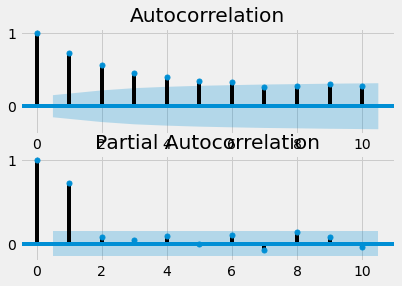

In [22]:
fig, axes=plt.subplots(2,1)
plot_acf(DMFM_nor, lags=10, ax=axes[0])
plot_pacf(DMFM_nor, lags=10, ax=axes[1])
plt.show()

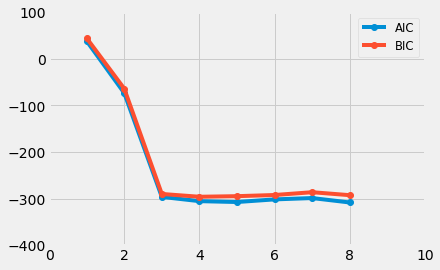

In [23]:
AIC, BIC = AIC_BIC_withOrderRange(DMFM_nor, p=3, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(1,0,0), 4:(1,0,1), 5:(1,0,2), 6:(2,0,0), 7:(2,0,1), 8:(2,0,2)

In [24]:
AIC, BIC

(array([ 211.56329257,   37.75239585,  -73.59158182, -296.24139742,
        -305.36197484, -307.22431142, -301.59349899, -298.74108078,
        -308.20963659]),
 array([ 214.69319128,   44.01219328,  -64.20188568, -289.98159999,
        -295.9722787 , -294.70471656, -292.20380284, -286.22148592,
        -292.56014301]))

We will run again 3:(1,0,0), 4:(1,0,1), 5:(1,0,2), 6:(2,0,0), 7:(2,0,1), 8:(2,0,2)

In [25]:
mod_orders = [
    (1,0,0),
    (1,0,1),
    (1,0,2),
    (2,0,0),
    (2,0,1),
    (2,0,2)
]

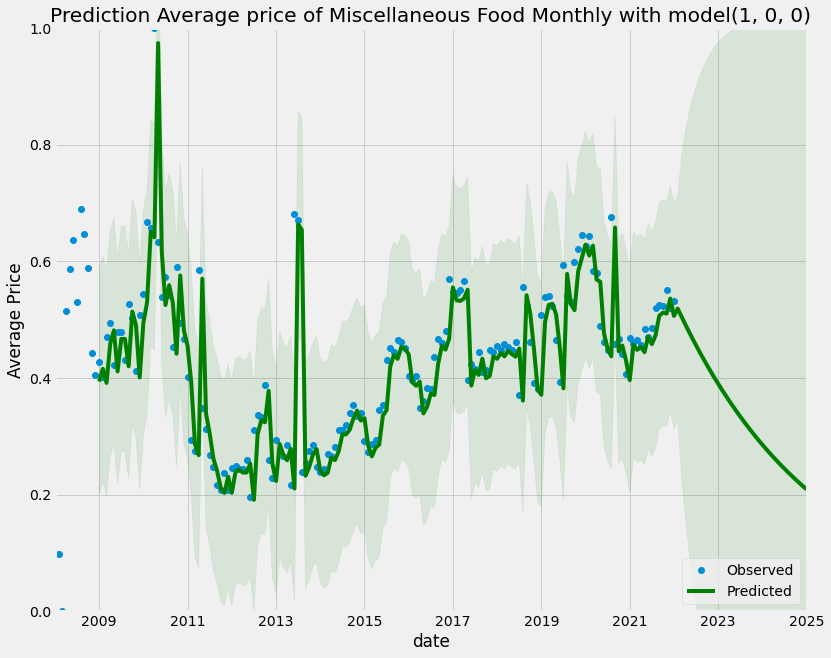

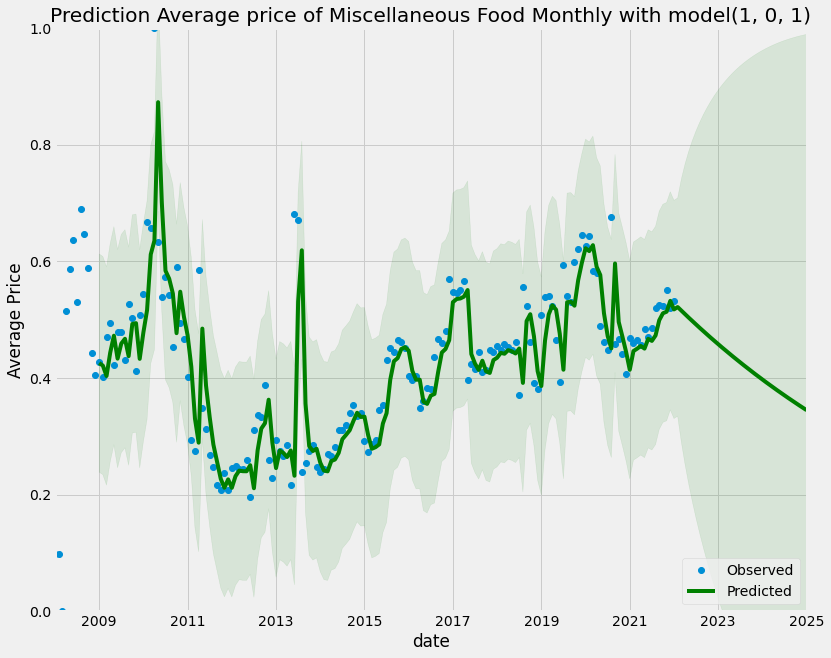

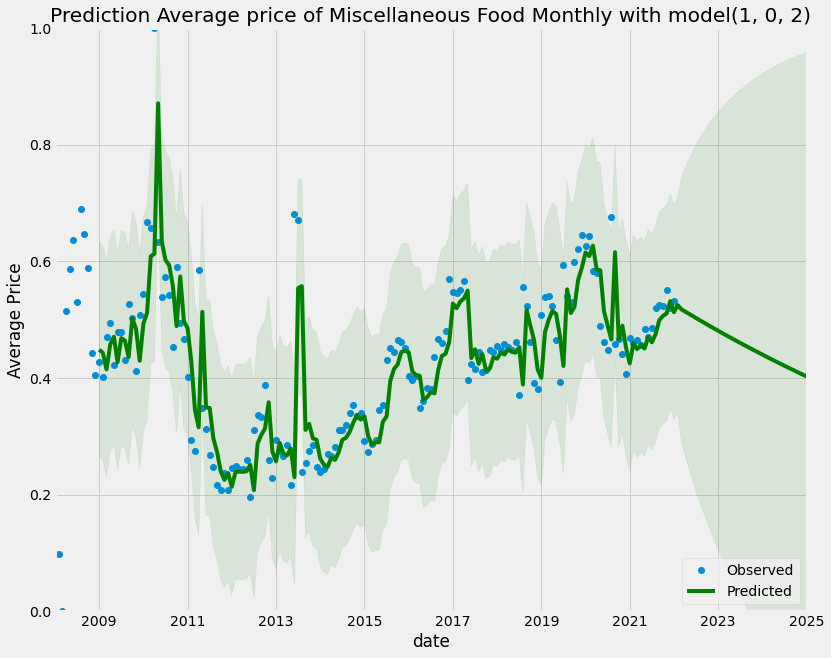

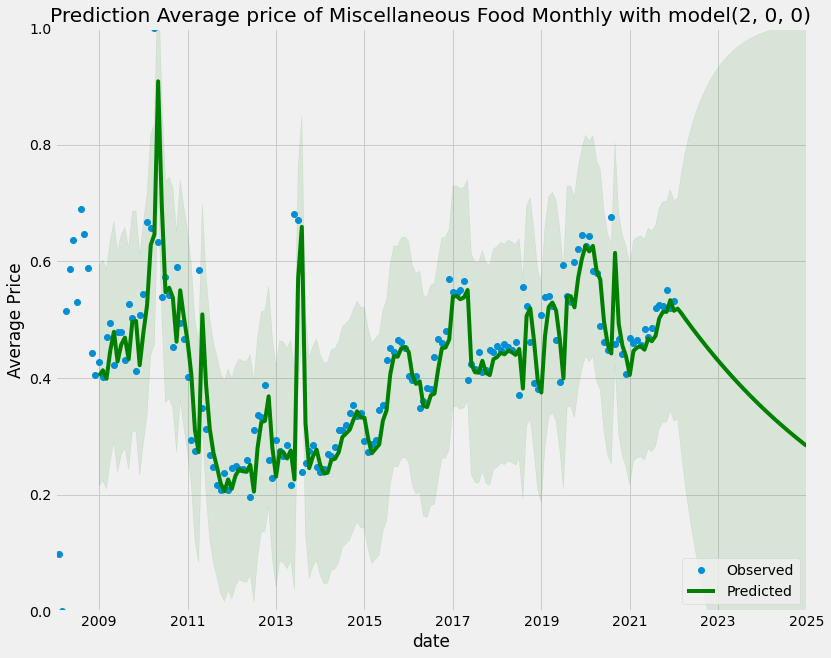

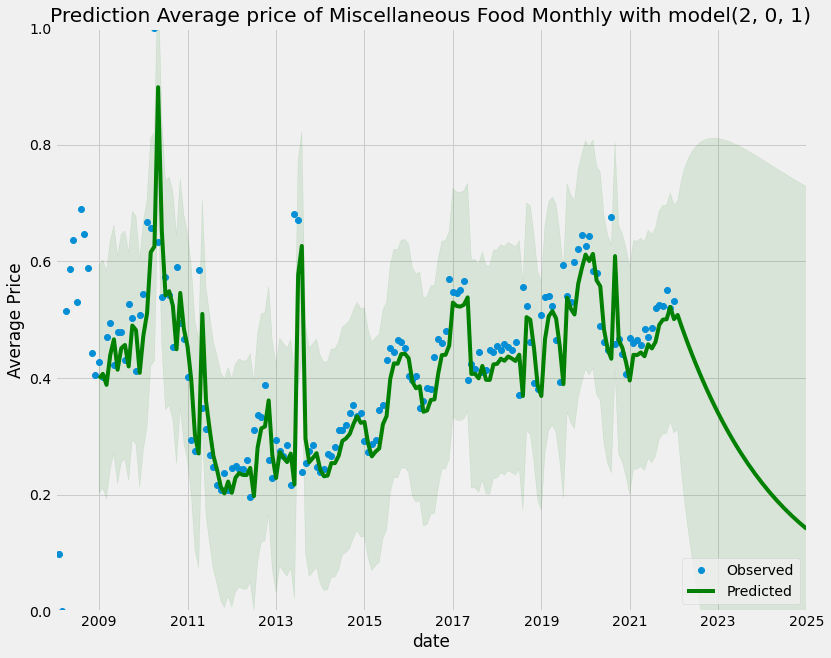

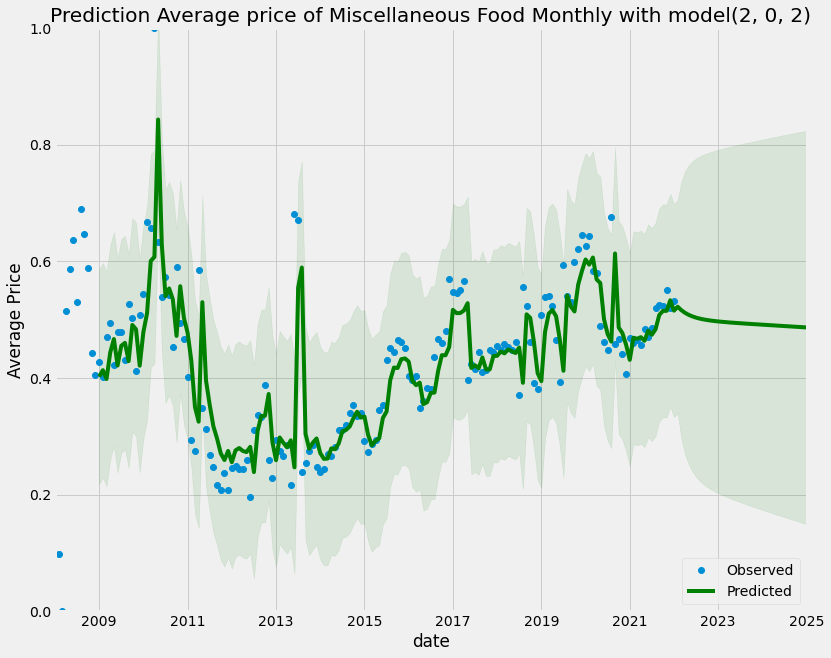

In [26]:
DMFM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DMFM_nor, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Miscellaneous Food Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DMFM_models.append(model)

Now we choose (1,0,2)

In [27]:
DMFM_model = DMFM_models[2]

In [28]:
DMFM_pred_normalized = DMFM_model.predict(pred_st_date, pred_end_date)
DMFM_pred_normalized

2009-01-01    0.448622
2009-02-01    0.443311
2009-03-01    0.414763
2009-04-01    0.457407
2009-05-01    0.470760
                ...   
2024-09-01    0.414800
2024-10-01    0.411743
2024-11-01    0.408709
2024-12-01    0.405698
2025-01-01    0.402709
Freq: MS, Length: 193, dtype: float64

We need to un-normalized the predicted value to get actual price

In [29]:
mask = (DMFM_nor.index>=pred_st_date) & (DMFM_nor.index<=pred_end_date)
DMFM_pred = DMFM_nor.loc[mask]
DMFM_pred

,price
date,
2009-01-01,0.426735
2009-02-01,0.402003
2009-03-01,0.470373
2009-04-01,0.494425
2009-05-01,0.422271
...,...
2021-09-01,0.525553
2021-10-01,0.524031
2021-11-01,0.550351


In [30]:
pred_date = DMFM_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2009-01-01', '2009-02-01', '2009-03-01', '2009-04-01',
               '2009-05-01', '2009-06-01', '2009-07-01', '2009-08-01',
               '2009-09-01', '2009-10-01',
               ...
               '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01',
               '2024-07-01', '2024-08-01', '2024-09-01', '2024-10-01',
               '2024-11-01', '2024-12-01'],
              dtype='datetime64[ns]', length=192, freq='MS')

In [31]:
DMFM_pred_normalized_df = pd.DataFrame(DMFM_pred_normalized)
DMFM_pred_normalized_df = DMFM_pred_normalized_df[:-1] # the last index doesn't need
DMFM_pred_normalized_df

,0
2009-01-01,0.448622
2009-02-01,0.443311
2009-03-01,0.414763
2009-04-01,0.457407
2009-05-01,0.470760
...,...
2024-08-01,0.417879
2024-09-01,0.414800
2024-10-01,0.411743
2024-11-01,0.408709


##### Un-normalization data

In [32]:
DMFM_pred_act = scaler.inverse_transform(DMFM_pred_normalized_df)
DMFM_pred_act_df = pd.DataFrame(DMFM_pred_act)
DMFM_pred_act_df['date'] = pred_date
DMFM_pred_act_df.columns = ['Predicted Price', 'date']
DMFM_pred_act_df.set_index('date',  inplace=True)
DMFM_pred_act_df

,Predicted Price
date,
2009-01-01,398.801276
2009-02-01,395.514727
2009-03-01,377.850172
2009-04-01,404.236710
2009-05-01,412.499174
...,...
2024-08-01,379.778211
2024-09-01,377.873006
2024-10-01,375.981840


In [33]:
mask = (DMFM.index>=pred_st_date) & (DMFM.index<=pred_end_date)
DMFM_Act = DMFM.loc[mask]
DMFM_Act

,price
date,
2009-01-01,385.258000
2009-02-01,369.955000
2009-03-01,412.260000
2009-04-01,427.142000
2009-05-01,382.496000
...,...
2021-09-01,446.403333
2021-10-01,445.461538
2021-11-01,461.747045


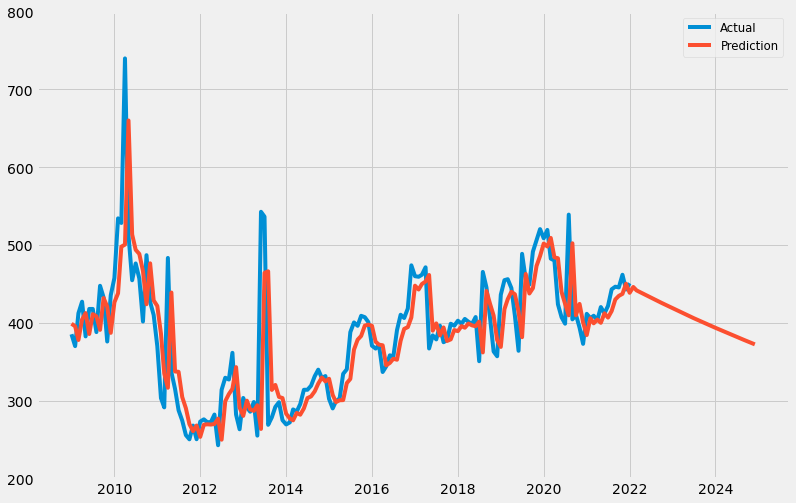

In [34]:
plt.figure(figsize=(12,8))
plt.plot(DMFM_Act, label="Actual")
plt.plot(DMFM_pred_act_df, label = "Prediction")
plt.legend(loc='best',fontsize='small')
plt.show()

### Linear Regression

In [35]:
temp_df = DMFM_nor.copy()
temp_df.reset_index(inplace =True)
temp_df

,date,price
0,2008-01-01,0.097945
1,2008-02-01,0.097945
2,2008-03-01,0.000000
3,2008-04-01,0.514227
4,2008-05-01,0.587688
...,...,...
164,2021-09-01,0.525553
165,2021-10-01,0.524031
166,2021-11-01,0.550351
167,2021-12-01,0.519787


In [36]:
temp_df['time'] = temp_df['date'].apply(lambda x: x.value)
mask = np.random.rand(len(temp_df)) < 0.8
train = temp_df[mask]
test = temp_df[~mask]
train, test

(          date     price                 time
 1   2008-02-01  0.097945  1201824000000000000
 2   2008-03-01  0.000000  1204329600000000000
 3   2008-04-01  0.514227  1207008000000000000
 4   2008-05-01  0.587688  1209600000000000000
 5   2008-06-01  0.636657  1212278400000000000
 ..         ...       ...                  ...
 164 2021-09-01  0.525553  1630454400000000000
 165 2021-10-01  0.524031  1633046400000000000
 166 2021-11-01  0.550351  1635724800000000000
 167 2021-12-01  0.519787  1638316800000000000
 168 2022-01-01  0.532736  1640995200000000000
 
 [138 rows x 3 columns],
           date     price                 time
 0   2008-01-01  0.097945  1199145600000000000
 12  2009-01-01  0.426735  1230768000000000000
 15  2009-04-01  0.494425  1238544000000000000
 27  2010-04-01  1.000000  1270080000000000000
 35  2010-12-01  0.466743  1291161600000000000
 40  2011-05-01  0.347812  1304208000000000000
 51  2012-04-01  0.244259  1333238400000000000
 58  2012-11-01  0.259751  135172

In [37]:
X_train = train.time
X_train = X_train.values.reshape((-1,1))
y_train = train['price'].values
X_train[:10], y_train[:10]

(array([[1201824000000000000],
        [1204329600000000000],
        [1207008000000000000],
        [1209600000000000000],
        [1212278400000000000],
        [1214870400000000000],
        [1217548800000000000],
        [1220227200000000000],
        [1222819200000000000],
        [1225497600000000000]], dtype=int64),
 array([0.0979453 , 0.        , 0.51422696, 0.58768795, 0.63665656,
        0.53088113, 0.69035503, 0.64667654, 0.58791098, 0.44360065]))

In [38]:
X_test = test.time
X_test = X_test.values.reshape((-1,1))
y_test = test['price'].values
X_test[:10], y_test[:10]

(array([[1199145600000000000],
        [1230768000000000000],
        [1238544000000000000],
        [1270080000000000000],
        [1291161600000000000],
        [1304208000000000000],
        [1333238400000000000],
        [1351728000000000000],
        [1354320000000000000],
        [1359676800000000000]], dtype=int64),
 array([0.0979453 , 0.42673476, 0.49442457, 1.        , 0.46674298,
        0.34781242, 0.24425936, 0.259751  , 0.22926205, 0.27447894]))

In [39]:
X = np.concatenate((X_train, X_test), axis = 0)
y = np.concatenate((y_train, y_test), axis = 0)

In [40]:
DMFM_linreg = LinearRegression().fit(X_train, y_train)

In [41]:
print('linear model coeff or slope (w): {}'.format(DMFM_linreg.coef_))
print('linear model intercept (b): {:.3f}'.format(DMFM_linreg.intercept_))
print('R-squared score (training): {:.3f}'.format(DMFM_linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'.format(DMFM_linreg.score(X_test, y_test)))

linear model coeff or slope (w): [2.45834553e-19]
linear model intercept (b): 0.081
R-squared score (training): 0.060
R-squared score (test): 0.016


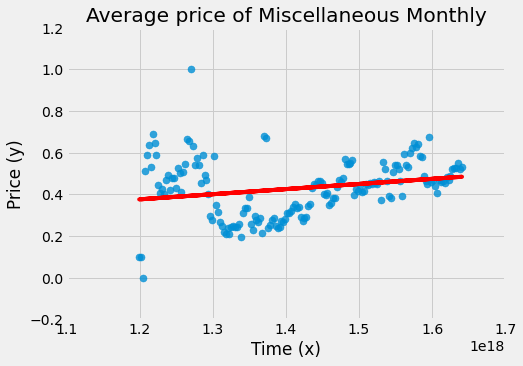

In [42]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, marker= 'o', s=50, alpha=0.8)
plt.plot(X, DMFM_linreg.coef_ * X + DMFM_linreg.intercept_, 'r-')
plt.title('Average price of Miscellaneous Monthly')
plt.xlabel('Time (x)')
plt.ylabel('Price (y)')
plt.show()

In [43]:
DMFM_linear_predict = pd.DataFrame(pd.date_range(start=pred_st_date,end=pred_end_date, freq='MS').to_pydatetime().tolist(), columns=['date'])
DMFM_linear_predict['time'] = DMFM_linear_predict['date'].apply(lambda x: x.value)
DMFM_linear_predict

,date,time
0,2009-01-01,1230768000000000000
1,2009-02-01,1233446400000000000
2,2009-03-01,1235865600000000000
3,2009-04-01,1238544000000000000
4,2009-05-01,1241136000000000000
...,...,...
188,2024-09-01,1725148800000000000
189,2024-10-01,1727740800000000000
190,2024-11-01,1730419200000000000
191,2024-12-01,1733011200000000000


In [44]:
time_predict = np.array(DMFM_linear_predict['time']).reshape((-1, 1))
DMFM_linear_predict['price'] = DMFM_linreg.predict(time_predict)
DMFM_linear_predict

,date,time,price
0,2009-01-01,1230768000000000000,0.383531
1,2009-02-01,1233446400000000000,0.384189
2,2009-03-01,1235865600000000000,0.384784
3,2009-04-01,1238544000000000000,0.385442
4,2009-05-01,1241136000000000000,0.386080
...,...,...,...
188,2024-09-01,1725148800000000000,0.505067
189,2024-10-01,1727740800000000000,0.505704
190,2024-11-01,1730419200000000000,0.506362
191,2024-12-01,1733011200000000000,0.507000


In [45]:
DMFM_linear_normalized_predict = DMFM_linear_predict.copy()
DMFM_linear_normalized_predict = DMFM_linear_normalized_predict[['date', 'price']]
DMFM_linear_normalized_predict.set_index('date', inplace=True)
DMFM_linear_normalized_predict

,price
date,
2009-01-01,0.383531
2009-02-01,0.384189
2009-03-01,0.384784
2009-04-01,0.385442
2009-05-01,0.386080
...,...
2024-09-01,0.505067
2024-10-01,0.505704
2024-11-01,0.506362


##### Unnormalized the data

In [46]:
DMFM_pred_act_linear = scaler.inverse_transform(DMFM_linear_normalized_predict)
DMFM_pred_act_linear_df = pd.DataFrame(DMFM_pred_act_linear)
DMFM_pred_act_linear_df['date'] = DMFM_linear_predict['date']
DMFM_pred_act_linear_df.columns = ['Predicted Price (KG)', 'date']
DMFM_pred_act_linear_df.set_index('date', inplace=True)
DMFM_pred_act_linear_df

,Predicted Price (KG)
date,
2009-01-01,358.524950
2009-02-01,358.932371
2009-03-01,359.300364
2009-04-01,359.707784
2009-05-01,360.102063
...,...
2024-09-01,433.726949
2024-10-01,434.121227
2024-11-01,434.528648
